<a href="https://colab.research.google.com/github/arraks1307/python-ai-course/blob/main/homework/lesson-11/solution.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Урок 11. Объединяем таблицы и работаем с датами

У нас есть список участников и отдельный файл с результатами. Как добавить результат к нужному человеку, если строки в файлах стоят в разном порядке? А если результатов ещё нет или у одного человека несколько попыток?

Сегодня разберём три задачи:
1. Собрать несколько файлов с одинаковыми столбцами в одну таблицу.
2. Найти соответствия между двумя таблицами и поставить данные рядом.
3. Прочитать дату из CSV, выбрать нужный день и посчитать, сколько времени прошло.

Начнём с трёх участников и нескольких строк результатов. Затем применим те же действия к Titanic и небольшому учебному журналу.


## Как работать

В начале каждого раздела — пример с готовым кодом. Прочитайте вопрос, посмотрите таблицы, попробуйте предсказать результат и запустите ячейку. Затем выполните похожее задание самостоятельно.

P1–P4 делаем на занятии, H1–H3 — дома. Код пишите в подготовленных ячейках, а пояснения — вместо `? ВЫВОДЫ`. `pass` — место для вашего кода.

Сохраните работу как `homework/lesson-11/solution.ipynb`. Готовая ячейка в конце запишет три файла в папку data: `titanic_lesson11.csv`, `submission_audit.csv`, `daily_submissions.csv`. Загрузите их вместе с notebook. Срок сообщит преподаватель.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display
plt.rcParams.update({"font.family":"DejaVu Sans", "font.size":12, "figure.facecolor":"white"})

# Это готовое оформление учебных схем, а не задание на Matplotlib.
def draw_table(ax, table, title, key=None):
    ax.axis("off")
    ax.set_title(title, fontsize=13, pad=14)
    shown = table.astype(object).where(table.notna(), "—")
    artist = ax.table(cellText=shown.values, colLabels=shown.columns,
                      cellLoc="center", colLoc="center", loc="center")
    artist.auto_set_font_size(False)
    artist.set_fontsize(11)
    artist.scale(1, 1.8)
    for (row, col), item in artist.get_celld().items():
        item.set_edgecolor("#B7C6D1")
        if row == 0:
            item.set_facecolor("#D8E8F2")
            item.set_text_props(weight="bold")
        elif key is not None and shown.columns[col] == key:
            key_colors={101:"#DCEEDB",102:"#D9EAF7",103:"#F8E7CC",104:"#E8DDF4"}
            value=table.iloc[row-1,col]
            item.set_facecolor(key_colors.get(value,"#DCEEDB"))
    return artist


## 🟨❗ Наша задача: собрать результаты участников

Есть список из трёх человек: Аня, Борис и Вера. В другом файле записаны результаты упражнения, но вместо имён — номера участников.

| Поле | Что означает |
|---|---|
| student_id | Номер участника: 101, 102 или другой |
| name | Имя |
| score | Баллы за упражнение |

Посмотрите на таблицы ниже. **Найдите вручную балл Ани:** сначала её номер в списке, затем тот же номер в результатах. Не соединяйте строки просто по порядку.

У кого из списка нет результата? Есть ли результат для номера, которого нет в списке?


In [2]:
demo_people = pd.DataFrame({"student_id":[101,102,103], "name":["Аня","Борис","Вера"]})
demo_scores = pd.DataFrame({"student_id":[102,101,104], "score":[8,10,7]})
display(demo_people)
display(demo_scores)
print("Первая строка результатов — 102, а первая строка людей — 101. Позиции не совпадают.")


,student_id,name
0,101,Аня
1,102,Борис
2,103,Вера


,student_id,score
0,102,8
1,101,10
2,104,7


Первая строка результатов — 102, а первая строка людей — 101. Позиции не совпадают.


## 🟨❗ Шаг 1. Соберём результаты из двух файлов

Представим, что результаты прислали двумя порциями: в первой две записи, во второй одна. Столбцы у них одинаковые — номер участника и балл. Хотим получить один список из трёх записей.

**Действие вручную:** переписываем строки первой таблицы, затем дописываем снизу строки второй. В pandas это делает `concat`.

```python
demo_scores = pd.concat([demo_batch1, demo_batch2], ignore_index=True)
```

В квадратных скобках перечисляем таблицы. `ignore_index=True` заново нумерует строки результата с нуля. Номера участников в student_id остаются прежними.


,student_id,score
0,102,8
1,101,10
2,104,7


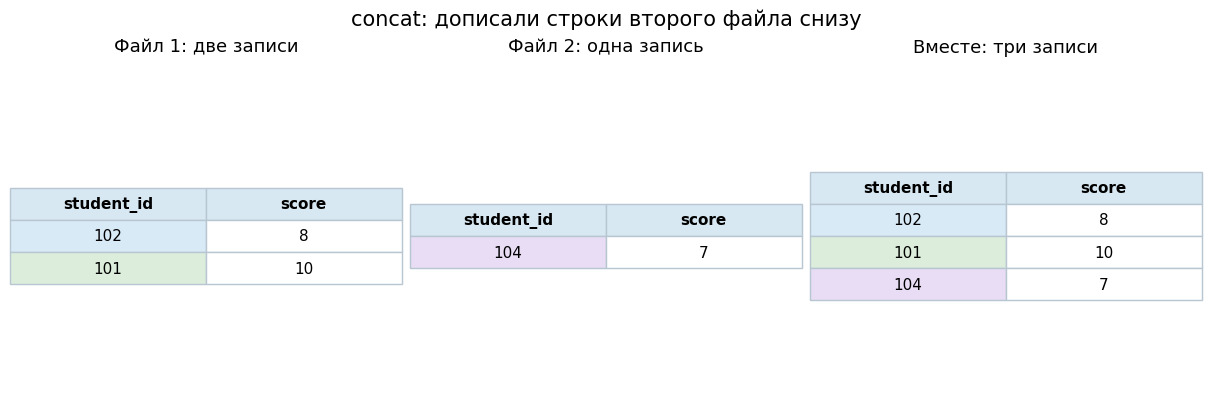

In [3]:
demo_batch1 = pd.DataFrame({"student_id":[102,101], "score":[8,10]})
demo_batch2 = pd.DataFrame({"student_id":[104], "score":[7]})
demo_scores = pd.concat([demo_batch1, demo_batch2], ignore_index=True)
display(demo_scores)
fig, axes = plt.subplots(1,3,figsize=(12,4),layout="constrained")
draw_table(axes[0],demo_batch1,"Файл 1: две записи","student_id")
draw_table(axes[1],demo_batch2,"Файл 2: одна запись","student_id")
draw_table(axes[2],demo_scores,"Вместе: три записи","student_id")
fig.suptitle("concat: дописали строки второго файла снизу",fontsize=15)
plt.show()
assert len(demo_scores)==len(demo_batch1)+len(demo_batch2)


**Прочитайте рисунок:** было две строки и одна строка, стало три. Столбцы те же. Мы добавили записи, но пока не искали, кому они принадлежат.

Если добавить первую порцию ещё раз, её записи повторятся: concat не проверяет, что файл уже был добавлен. Поэтому после сборки проверяем номера самих записей, а не только нумерацию строк слева.

Перед concat сравниваем названия столбцов. `score` и `points` для pandas — разные поля, даже если человек подразумевал под обоими «баллы».


## 🟨❗ Шаг 2. Подпишем результат каждому человеку

Теперь есть две таблицы: **люди** и **результаты**. Хотим получить одну строку на человека с именем и баллом.

Сделаем это вручную:
1. Берём Аню. Её номер — **101**.
2. Ищем **101** в результатах. Находим балл **10**.
3. Ставим 10 рядом с именем Ани.
4. Повторяем для Бориса: номер **102**, балл **8**.
5. Для Веры **103** результата нет. Оставляем пустое место, а не ставим ноль.

Общий столбец student_id называют **ключом соединения**: по нему ищем соответствующие строки. Команда `merge` выполняет этот поиск.

```python
demo_left = demo_people.merge(demo_scores, on="student_id", how="left")
```

- `demo_people` — начинаем со списка людей;
- `demo_scores` — здесь ищем их результаты;
- `on="student_id"` — сравниваем номера участников;
- `how="left"` — оставляем всех людей из первой таблицы, даже без результата.

Посмотрите, совпал ли рисунок с вашим ручным ответом. Порядок строк справа нам не помешал.


,student_id,name,score
0,101,Аня,10.0
1,102,Борис,8.0
2,103,Вера,NaN


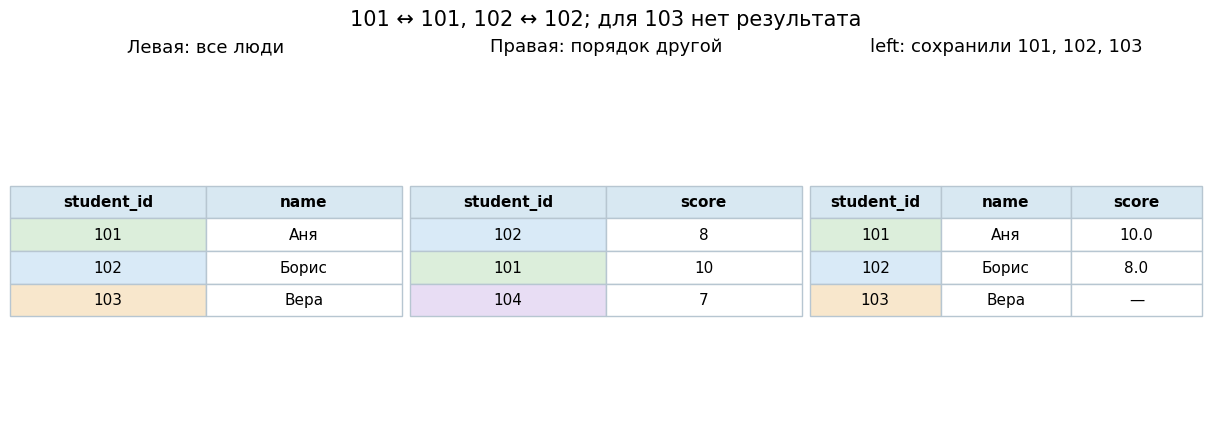

In [4]:
demo_left = demo_people.merge(demo_scores, on="student_id", how="left")
display(demo_left)
fig, axes = plt.subplots(1,3,figsize=(12,4.3),layout="constrained")
draw_table(axes[0],demo_people,"Левая: все люди","student_id")
draw_table(axes[1],demo_scores,"Правая: порядок другой","student_id")
draw_table(axes[2],demo_left,"left: сохранили 101, 102, 103","student_id")
fig.suptitle("101 ↔ 101, 102 ↔ 102; для 103 нет результата",fontsize=15)
plt.show()


### Кого оставить, если совпали не все номера?

В примере есть две особые записи: **103** есть в списке людей, но нет в результатах; **104** есть в результатах, но нет в списке людей.

| Что хотим получить | Что пишем | Что будет в нашем примере |
|---|---|---|
| Весь список людей, баллы при наличии | how="left" | 101, 102, 103; у Веры пустой балл |
| Только людей, для которых есть результат | how="inner" | 101 и 102; Вера не войдёт |
| Всё из обеих таблиц, чтобы разобраться с пропусками | how="outer" | 101, 102, 103, 104; у 104 неизвестно имя |

Выбор зависит от задачи. Для ведомости всей группы удобен left. Для поиска несовпавших записей — outer. Ни один вариант не является «лучшим всегда».


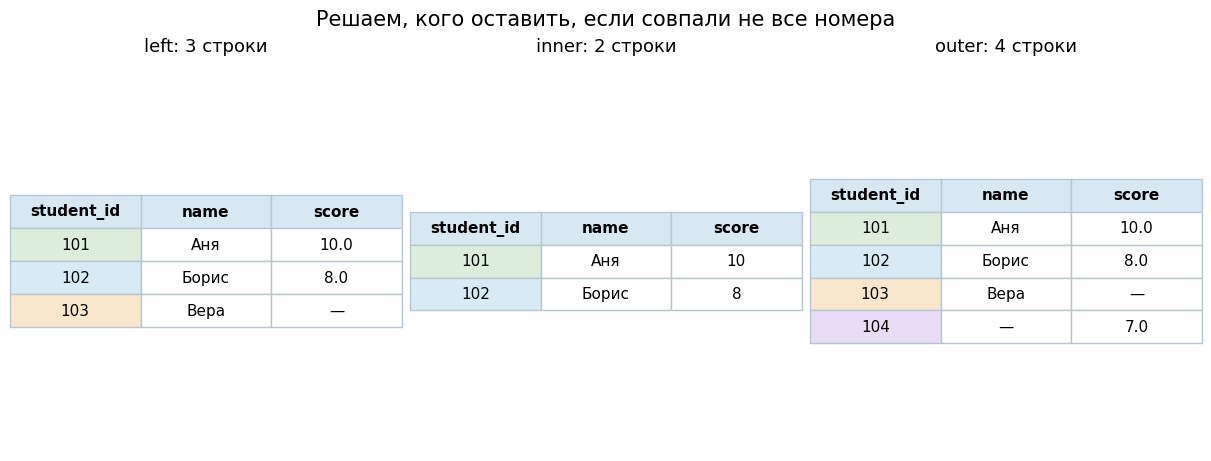

In [5]:
fig, axes = plt.subplots(1,3,figsize=(12,4.5),layout="constrained")
for ax, mode in zip(axes,["left","inner","outer"]):
    joined = demo_people.merge(demo_scores,on="student_id",how=mode)
    draw_table(ax,joined,f"{mode}: {len(joined)} строки","student_id")
fig.suptitle("Решаем, кого оставить, если совпали не все номера",fontsize=15)
plt.show()


### Как найти записи без пары

В большом результате трудно искать пропуски глазами. Добавим `indicator=True` — pandas подпишет происхождение каждой строки в новом столбце `_merge`.

| Подпись | Как читать |
|---|---|
| both | Номер найден в обеих таблицах |
| left_only | Номер есть только в левой таблице |
| right_only | Номер есть только в правой таблице |

Найдите 103 и 104 в выводе. Что именно отсутствует у каждого?


In [6]:
demo_audit = demo_people.merge(demo_scores, on="student_id", how="outer", indicator=True)
display(demo_audit)
print("103: нет результата. 104: нет имени в списке людей.")


,student_id,name,score,_merge
0,101,Аня,10.0,both
1,102,Борис,8.0,both
2,103,Вера,NaN,left_only
3,104,NaN,7.0,right_only


103: нет результата. 104: нет имени в списке людей.


## 🟨❗ Шаг 3. Проверим: один номер — одна строка?

До сих пор номер участника встречался в каждой таблице один раз. Теперь представим, что у 101 две попытки, а в другой таблице для него три записи.

Merge найдёт все сочетания: A с X, Y, Z; затем B с X, Y, Z. **Две строки умножились на три — получилось шесть.** Это шесть сочетаний записей, а не шесть людей.

Посмотрите на рисунок и найдите три строки, которые появились из попытки A.

Если мы ожидали одну строку на человека, такой результат требует проверки. Для этого есть параметр validate:

- `one_to_one` — номер должен встречаться по одному разу в обеих таблицах;
- `many_to_one` — слева номер может повторяться, справа должна быть одна строка на номер.

Например, пассажиров третьего класса много, но строка «3 → Третий класс» в справочнике нужна одна. Это many_to_one: много пассажиров — одна подпись класса.


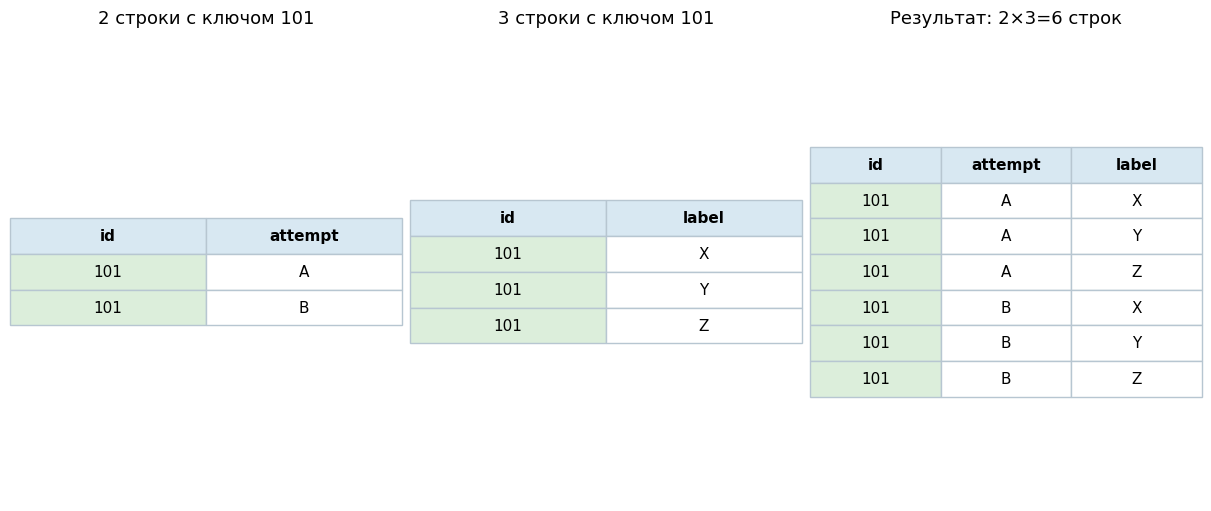

Проверка остановила соединение: ключи не уникальны. Это ожидаемая демонстрация защиты.


In [7]:
demo_repeated_left=pd.DataFrame({"id":[101,101],"attempt":["A","B"]})
demo_repeated_right=pd.DataFrame({"id":[101,101,101],"label":["X","Y","Z"]})
demo_six=demo_repeated_left.merge(demo_repeated_right,on="id")
fig,axes=plt.subplots(1,3,figsize=(12,5),layout="constrained")
draw_table(axes[0],demo_repeated_left,"2 строки с ключом 101","id")
draw_table(axes[1],demo_repeated_right,"3 строки с ключом 101","id")
draw_table(axes[2],demo_six,"Результат: 2×3=6 строк","id")
plt.show()
try:
    demo_repeated_left.merge(demo_repeated_right,on="id",validate="one_to_one")
except pd.errors.MergeError:
    print("Проверка остановила соединение: ключи не уникальны. Это ожидаемая демонстрация защиты.")


### Три вопроса перед соединением

1. **Что означает строка?** Один человек или одна попытка? Это разные таблицы.
2. **По какому полю ищем совпадение?** Нужен номер нужного объекта, а не случайный порядок строк.
3. **Может ли ключ повторяться?** В списке людей обычно нет; в журнале попыток — да.

`table["id"].is_unique` отвечает, уникальны ли номера. `table["id"].duplicated(keep=False)` отмечает все строки с повторившимся номером, чтобы их можно было посмотреть. Это проверка, а не команда удаления.

После соединения смотрим число строк и пропуски. Если ожидали сохранить 891 пассажира, а получили другое число, сначала выясняем причину.


## Загружаем файлы для практики

Распакуйте Student ZIP. В нём notebook и восемь CSV. В Jupyter оставьте их в одной папке. В Colab загрузите CSV в панель «Файлы» или включите UPLOAD_IN_COLAB в следующей ячейке.

`DATA_DIR="."` — файлы рядом с notebook. Если положили их в папку data, укажите `DATA_DIR="data"`.

| Таблицы | Для чего нужны |
|---|---|
| passengers_part1 и passengers_part2 | Две части Titanic, которые соберём через concat |
| titanic | Полный исходник для проверки результата |
| class_labels и port_labels | Расшифровки класса и кода порта |
| submissions | Небольшой учебный журнал с датами |
| assignment_schedule | Расписание этого журнала |
| assignment_schedule_conflict | Пример расписания с ошибкой для ДЗ |

Журнал вымышленный, а не журнал нашей группы. Время в нём указано по Москве. Titanic и журнал — разные наборы данных.


In [8]:
DATA_DIR = "."
UPLOAD_IN_COLAB = False
PREVIOUS_FILE = None  # Необязательно: путь к вашему titanic_lesson10.csv.


In [9]:
required_files=["titanic.csv","passengers_part1.csv","passengers_part2.csv","class_labels.csv",
                "port_labels.csv","submissions.csv","assignment_schedule.csv","assignment_schedule_conflict.csv"]
if UPLOAD_IN_COLAB:
    from google.colab import files
    uploaded=files.upload()
    print("Загружено файлов:",len(uploaded))
data_root=Path(DATA_DIR)
missing_files=[name for name in required_files if not (data_root/name).is_file()]
if missing_files:
    raise FileNotFoundError("Положите CSV комплекта в DATA_DIR. Не найдены: "+", ".join(missing_files))
raw=pd.read_csv(data_root/"titanic.csv",encoding="utf-8-sig")
part1=pd.read_csv(data_root/"passengers_part1.csv",encoding="utf-8-sig")
part2=pd.read_csv(data_root/"passengers_part2.csv",encoding="utf-8-sig")
class_labels=pd.read_csv(data_root/"class_labels.csv",encoding="utf-8-sig")
port_labels=pd.read_csv(data_root/"port_labels.csv",encoding="utf-8-sig")
submissions=pd.read_csv(data_root/"submissions.csv",encoding="utf-8-sig",keep_default_na=False)
schedule=pd.read_csv(data_root/"assignment_schedule.csv",encoding="utf-8-sig")
schedule_conflict=pd.read_csv(data_root/"assignment_schedule_conflict.csv",encoding="utf-8-sig")
source_columns=list(raw.columns)
assert len(raw)==891 and raw["PassengerId"].is_unique and raw["Survived"].sum()==342
# Готовое продолжение известных признаков уроков 8–10; предмет сегодняшней практики — объединение.
def continue_previous_stage(source):
    base=source.copy()
    base["Family_size"]=base["SibSp"]+base["Parch"]+1
    base["Is_alone"]=base["Family_size"]==1
    base["Age_group"]="Неизвестный"
    base.loc[base["Age"]<18,"Age_group"]="Младше18"
    base.loc[base["Age"]>=18,"Age_group"]="От18"
    base["Age_known"]=base["Age"].notna()
    base["Embarked_for_analysis"]=base["Embarked"].fillna("Неизвестно")
    if PREVIOUS_FILE:
        previous=pd.read_csv(PREVIOUS_FILE,encoding="utf-8-sig")
        pd.testing.assert_frame_equal(previous[source_columns].sort_values("PassengerId").reset_index(drop=True),source.sort_values("PassengerId").reset_index(drop=True),check_dtype=False)
        known_features=["Family_size","Is_alone","Age_group","Age_known","Embarked_for_analysis"]
        pd.testing.assert_frame_equal(previous.set_index("PassengerId")[known_features].sort_index(),base.set_index("PassengerId")[known_features].sort_index(),check_dtype=False)
        return previous.sort_values("PassengerId").reset_index(drop=True)
    print("Добавлены знакомые признаки: размер семьи, возрастная группа и другие.")
    return base
combined=passengers=named=log_dates=audit=stage_result=daily=None
print("Готовы части Titanic:",len(part1),"+",len(part2),"; учебных записей журнала:",len(submissions))


Готовы части Titanic: 450 + 441 ; учебных записей журнала: 8


## ⭐ Практика P1. Соберите две части Titanic

**Нужно:** одна пассажирская таблица вместо двух файлов.

1. Посмотрите размеры part1 и part2: 450 и 441 строка.
2. Сравните названия их столбцов.
3. Соедините строки через concat и назовите результат combined.
4. Проверьте: получилось 891 строка, номера PassengerId не повторяются.
5. Выполните готовую проверку из подсказки: она сверит значения с полным исходником raw.
6. Запустите `passengers = continue_previous_stage(combined)`. Готовая функция возвращает знакомые признаки предыдущих уроков; дальше работаем с passengers.

**Объясните:** что произойдёт, если случайно добавить part1 два раза?


In [10]:
print("Размеры:", part1.shape, part2.shape)
print("Столбцы совпадают:", part1.columns.equals(part2.columns))
print("Различия в названиях:", set(part1.columns).symmetric_difference(part2.columns))

combined = pd.concat([part1, part2], axis=0, ignore_index=True)

print("Строк в combined:", combined.shape[0])
print("Повторов PassengerId:", combined["PassengerId"].duplicated().sum())
assert combined.shape[0] == len(part1) + len(part2) == 891
assert combined["PassengerId"].nunique() == 891

pd.testing.assert_frame_equal(combined[source_columns], raw, check_dtype=False)

passengers = continue_previous_stage(combined)
print("Готово: passengers содержит", len(passengers), "строк")

Размеры: (450, 12) (441, 12)
Столбцы совпадают: True
Различия в названиях: set()
Строк в combined: 891
Повторов PassengerId: 0
Добавлены знакомые признаки: размер семьи, возрастная группа и другие.
Готово: passengers содержит 891 строк


### ❓ Вопросы и выводы

Что сделает повторное добавление part1? Почему новый индекс не защищает от повторных PassengerId?

**ВЫВОДЫ:** Если добавить `part1` дважды, в таблице станет 450 + 450 + 441 = 1341 строка вместо 891. Первые 450 пассажиров окажутся в ней два раза, и их `PassengerId` повторится: `duplicated().sum()` покажет 450, а `is_unique` вернёт `False`. Параметр `ignore_index=True` просто нумерует строки заново, от 0 до 1340. Он не знает, кто такой пассажир, поэтому индекс выглядит уникальным, хотя данные задвоены. Дубли исказят подсчёты: число пассажиров и долю выживших. Поэтому проверять нужно уникальность `PassengerId`, а не индекса.

## ⭐ Практика P2. Добавьте название класса пассажира

В passengers класс записан числом Pclass. В class_labels есть его подпись: например, 3 → «Третий класс». Нужно добавить подпись каждому пассажиру, сохранив всех людей.

1. Покажите class_labels и найдите строку для класса 3. Порядок строк в нём другой — это нормально.
2. Присоедините справочник к passengers по Pclass. Используйте left. Результат назовите named.
3. Добавьте `validate="many_to_one"`: пассажиров одного класса много, а подпись класса справа должна быть одна.
4. Добавьте `indicator=True` и проверьте, что во всех строках `_merge` равно both.
5. Проверьте 891 строку, уникальность PassengerId и отсутствие пропусков Class_label.
6. Удалите служебный столбец: `named = named.drop(columns=["_merge"])`.

Покажите PassengerId, Pclass и Class_label для первых пяти пассажиров. Почему не соединяли таблицы по порядку строк?


In [11]:
display(class_labels)
print(class_labels[class_labels["Pclass"] == 3])

named = pd.merge(
    left=passengers,
    right=class_labels,
    how="left",
    on="Pclass",
    validate="many_to_one",
    indicator=True,
)

print("Строк:", len(named), "| PassengerId уникален:", named["PassengerId"].is_unique)
print(named["_merge"].value_counts())
assert len(named) == len(passengers) == 891
assert named["PassengerId"].is_unique
assert named["_merge"].eq("both").all()
assert named["Class_label"].notna().all()

named = named.drop(columns=["_merge"])
display(named[["PassengerId", "Pclass", "Class_label"]].head(5))

,Pclass,Class_label
0,3,Третий класс
1,1,Первый класс
2,2,Второй класс


   Pclass   Class_label
0       3  Третий класс
Строк: 891 | PassengerId уникален: True
_merge
both          891
left_only       0
right_only      0
Name: count, dtype: int64


,PassengerId,Pclass,Class_label
0,1,3,Третий класс
1,2,1,Первый класс
2,3,3,Третий класс
3,4,1,Первый класс
4,5,3,Третий класс


### ❓ Вопросы и выводы

Почему здесь many_to_one, а не one_to_one? Потеряем ли людей, если одной подписи в справочнике не будет?

**ВЫВОДЫ:** В `class_labels` каждому `Pclass` соответствует одна подпись, а у пассажиров класс повторяется (сотни людей в третьем классе). Одна строка справа на много строк слева — это `many_to_one`. `one_to_one` потребовал бы уникальный `Pclass` и у пассажиров, а это неверно. Если бы подписи для какого-то класса в справочнике не оказалось, при `how="left"` никто из 891 пассажира не потерялся бы, а в `Class_label` появился бы пропуск (`NaN`). `inner` удалил бы таких пассажиров. Здесь все строки `_merge` равны `both`, подпись есть у всех.

## 🟨❗ Шаг 4. Превратим текст в дату

В CSV время записано символами: `"2026-10-22 18:30"`. Пока это текст, pandas не может обращаться с ним как с календарной датой. Преобразуем его командой to_datetime.

```python
pd.to_datetime(текст, format="%Y-%m-%d %H:%M", errors="coerce")
```

Формат говорит, как читать запись:

| Часть | Значение в примере |
|---|---|
| %Y | Год: 2026 |
| %m | Месяц: 10 |
| %d | День: 22 |
| %H:%M | Часы и минуты: 18:30 |

А что делать с 30 февраля или пустой строкой? При `errors="coerce"` получится **NaT — неизвестная дата**. Исходную запись оставим рядом: так видно, что именно нужно проверить. Команда не исправляет ошибочную дату за нас.


,text,parsed
0,2026-10-20 12:00,2026-10-20 12:00:00
1,2026-02-30 12:00,NaT
2,,NaT


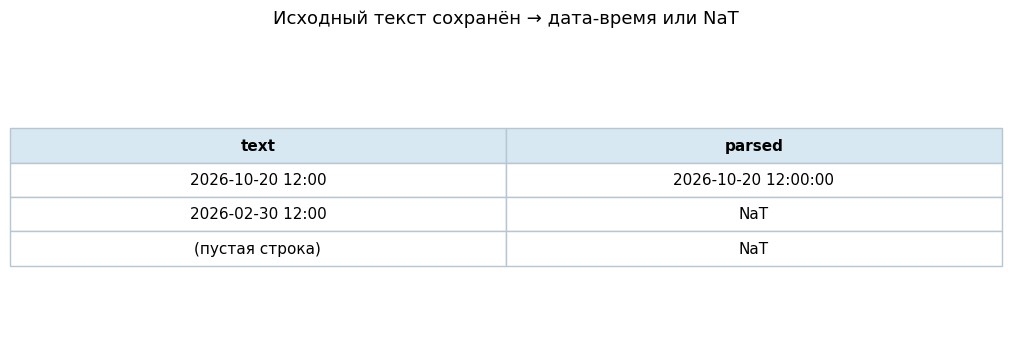

Не удалось получить дату: 2


In [12]:
demo_dates=pd.DataFrame({"text":["2026-10-20 12:00","2026-02-30 12:00",""]})
demo_dates["parsed"]=pd.to_datetime(demo_dates["text"],format="%Y-%m-%d %H:%M",errors="coerce")
display(demo_dates)
schema_dates=demo_dates.copy()
schema_dates["text"]=schema_dates["text"].replace("","(пустая строка)")
schema_dates["parsed"]=schema_dates["parsed"].astype("string").fillna("NaT")
fig,ax=plt.subplots(figsize=(10,3.5),layout="constrained")
draw_table(ax,schema_dates,"Исходный текст сохранён → дата-время или NaT")
plt.show()
print("Не удалось получить дату:",demo_dates["parsed"].isna().sum())


### Из даты можно взять год, месяц и день

После преобразования у столбца появляются календарные свойства: `.dt.year` — год, `.dt.month` — месяц, `.dt.day` — день месяца. Например, из 22 октября 2026 года получим 2026, 10 и 22.

Если нужна подпись для таблицы или отчёта, `.dt.strftime("%d.%m.%Y")` напишет «22.10.2026». Это текст для показа; исходный столбец дат оставляем для расчётов.


In [13]:
demo_calendar = pd.DataFrame({"text":["2026-10-22 17:30", "2026-10-23 09:00"]})
demo_calendar["at"] = pd.to_datetime(demo_calendar["text"], format="%Y-%m-%d %H:%M")
demo_calendar["year"] = demo_calendar["at"].dt.year
demo_calendar["month"] = demo_calendar["at"].dt.month
demo_calendar["day"] = demo_calendar["at"].dt.day
demo_calendar["label"] = demo_calendar["at"].dt.strftime("%d.%m.%Y")
display(demo_calendar)


,text,at,year,month,day,label
0,2026-10-22 17:30,2026-10-22 17:30:00,2026,10,22,22.10.2026
1,2026-10-23 09:00,2026-10-23 09:00:00,2026,10,23,23.10.2026


### Выберем события одного дня

Нужны все записи 22 октября: начиная с 00:00 этого дня, но раньше 00:00 следующего. Так мы включим любое время внутри суток.

В условии ниже `>=` означает «не раньше», `<` — «раньше», `&` соединяет два условия словом «и». Скобки выделяют каждое сравнение.


In [14]:
demo_one_day = demo_calendar.loc[
    (demo_calendar["at"] >= pd.Timestamp("2026-10-22")) &
    (demo_calendar["at"] < pd.Timestamp("2026-10-23"))
]
display(demo_one_day)
print("В нашем маленьком примере за 22 октября одна запись.")


,text,at,year,month,day,label
0,2026-10-22 17:30,2026-10-22 17:30:00,2026,10,22,22.10.2026


В нашем маленьком примере за 22 октября одна запись.


### Посчитаем, насколько раньше или позже

Срок — 18:00. Сдача в 17:30 произошла на полчаса раньше, сдача в 18:30 — на полчаса позже.

Вычитаем **время срока из времени сдачи**. Получаем длительность: отрицательную до срока, нулевую на границе, положительную после. Чтобы выразить её в часах, берём общее число секунд и делим на 3600: `.dt.total_seconds() / 3600`.

Посмотрите на таблицу и линию времени ниже. Почему для 17:30 результат −0,5, а не +0,5?


,event,at,hours_from_deadline
0,Ранняя сдача,2026-10-22 17:30:00,-0.5
1,Ровно в срок,2026-10-22 18:00:00,0.0
2,После срока,2026-10-22 18:30:00,0.5


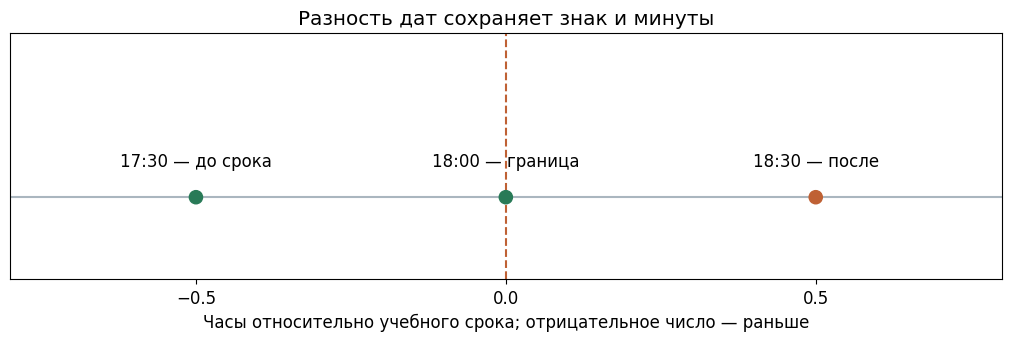

In [15]:
demo_clock=pd.DataFrame({"event":["Ранняя сдача","Ровно в срок","После срока"],
                        "text":["2026-10-22 17:30","2026-10-22 18:00","2026-10-22 18:30"]})
demo_clock["at"]=pd.to_datetime(demo_clock["text"],format="%Y-%m-%d %H:%M")
demo_deadline=pd.Timestamp("2026-10-22 18:00")
demo_clock["hours_from_deadline"]=(demo_clock["at"]-demo_deadline).dt.total_seconds()/3600
display(demo_clock[["event","at","hours_from_deadline"]])
fig,ax=plt.subplots(figsize=(10,3.3),layout="constrained")
ax.axhline(0,color="#AAB6BF")
ax.scatter([-0.5,0,0.5],[0,0,0],s=90,color=["#287A57","#287A57","#BF6134"],zorder=3)
for x,label in [(-0.5,"17:30 — до срока"),(0,"18:00 — граница"),(0.5,"18:30 — после")]:
    ax.annotate(label,(x,0),xytext=(0,22),textcoords="offset points",ha="center")
ax.axvline(0,color="#BF6134",linestyle="--")
ax.set(xticks=[-0.5,0,0.5],yticks=[],xlim=(-0.8,0.8),ylim=(-0.15,0.3),
       xlabel="Часы относительно учебного срока; отрицательное число — раньше",
       title="Разность дат сохраняет знак и минуты")
plt.show()


## ⭐ Практика P3. Разберите даты восьми записей

В submissions одна строка — одна сдача упражнения.

| Поле | Значение |
|---|---|
| submission_id | Номер записи, например S01 |
| participant_id | Номер участника |
| task_id | Задание A, B или другое |
| submitted_text | Время сдачи, пока записанное текстом |

1. Покажите все восемь строк.
2. Создайте копию: `log_dates = submissions.copy()`.
3. Прочитайте submitted_text через to_datetime и запишите даты в новый submitted_at. Используйте формат из примера и errors="coerce".
4. Покажите строки, где submitted_at неизвестен. Посмотрите на исходный текст: в чём проблема каждой записи?
5. Выведите год, месяц и день через `.dt.year`, `.dt.month`, `.dt.day`.
6. Выберите события 22 октября и назовите отбор on_oct22.

Для проверки: в полном журнале 8 строк, неизвестных времён 2, событий 22 октября — 2. Строки с неизвестным временем не удаляйте из log_dates.


In [16]:
display(submissions)

log_dates = submissions.copy()
log_dates["submitted_at"] = pd.to_datetime(
    log_dates["submitted_text"], format="%Y-%m-%d %H:%M", errors="coerce"
)

unknown = log_dates[log_dates["submitted_at"].isna()]
display(unknown[["submission_id", "submitted_text"]])

parts = pd.DataFrame({
    "submission_id": log_dates["submission_id"],
    "year": log_dates["submitted_at"].dt.year,
    "month": log_dates["submitted_at"].dt.month,
    "day": log_dates["submitted_at"].dt.day,
})
display(parts)

start = pd.Timestamp("2026-10-22")
end = pd.Timestamp("2026-10-23")
on_oct22 = log_dates[(log_dates["submitted_at"] >= start) & (log_dates["submitted_at"] < end)]
display(on_oct22)

print(len(log_dates), len(unknown), len(on_oct22))   # 8, 2, 2

,submission_id,participant_id,task_id,submitted_text
0,S01,101,A,2026-10-20 12:00
1,S02,102,A,2026-10-22 18:00
2,S03,103,A,2026-10-22 18:30
3,S04,104,A,2026-02-30 12:00
4,S05,101,B,2026-10-24 10:00
5,S06,102,B,
6,S07,103,B,2026-10-25 19:00
7,S08,104,X,2026-10-24 11:00


,submission_id,submitted_text
3,S04,2026-02-30 12:00
5,S06,


,submission_id,year,month,day
0,S01,2026.0,10.0,20.0
1,S02,2026.0,10.0,22.0
2,S03,2026.0,10.0,22.0
3,S04,NaN,NaN,NaN
4,S05,2026.0,10.0,24.0
5,S06,NaN,NaN,NaN
6,S07,2026.0,10.0,25.0
7,S08,2026.0,10.0,24.0


,submission_id,participant_id,task_id,submitted_text,submitted_at
1,S02,102,A,2026-10-22 18:00,2026-10-22 18:00:00
2,S03,103,A,2026-10-22 18:30,2026-10-22 18:30:00


8 2 2


### ❓ Вопросы и выводы

Какая запись не имеет времени, а какая содержит невозможную дату? Почему нельзя назвать обе просроченными?

**ВЫВОДЫ:** Запись S04 содержит невозможную дату `2026-02-30 12:00`: 30 февраля не существует, поэтому `to_datetime` с `errors="coerce"` вернул `NaT`. Запись S06 содержит пустую строку, поэтому времени у неё нет вообще. Итого неизвестных времён 2 из 8. Нельзя назвать обе записи просроченными: чтобы сравнить сдачу со сроком, нужно знать, когда она произошла, а у S04 и S06 этого времени нет. Поэтому они получают статус «Проверить дату» и остаются в таблице. События 22 октября — S02 и S03, всего 2 строки.

## ⭐ Практика P4. Добавьте к каждой сдаче её срок

В журнале есть время сдачи, а в schedule — срок задания. Чтобы их сравнить, сначала соединяем таблицы по task_id: сдача A должна получить срок A, а не соседнюю строку расписания.

**Сначала соединение:**
1. Присоедините schedule к log_dates по task_id через left. Назовите результат audit.
2. Добавьте many_to_one и indicator=True, как в P2.
3. Найдите строку left_only: для какого задания не нашлось расписания?

**Теперь время:**
4. Прочитайте opened_text и deadline_text как даты в opened_at и deadline_at.
5. Вычтите deadline_at из submitted_at и переведите разницу в часы. Столбец назовите hours_from_deadline.

**Наконец подпись результата:**
6. Создайте status со значением «Проверить дату».
7. Для известных дат поставьте «В срок», если сдача раньше срока или ровно в срок; «После срока», если позже.
8. Для задания без расписания поставьте «Нет срока».

Подсказка: `known = audit["submitted_at"].notna() & audit["deadline_at"].notna()` отмечает строки, где оба времени известны. Выбирайте их через `.loc`, прежде чем сравнивать даты.

Покажите номер записи, время сдачи, срок, разницу в часах и status. Все 8 записей должны сохраниться.


In [17]:
audit = pd.merge(
    log_dates, schedule,
    on="task_id", how="left", validate="many_to_one", indicator=True,
)
display(audit[audit["_merge"] == "left_only"][["submission_id", "task_id", "_merge"]])

fmt = "%Y-%m-%d %H:%M"
audit["opened_at"] = pd.to_datetime(audit["opened_text"], format=fmt, errors="coerce")
audit["deadline_at"] = pd.to_datetime(audit["deadline_text"], format=fmt, errors="coerce")

delta = audit["submitted_at"] - audit["deadline_at"]
audit["hours_from_deadline"] = delta / pd.Timedelta(hours=1)

audit["status"] = "Проверить дату"
known = audit["submitted_at"].notna() & audit["deadline_at"].notna()
late = known & (audit["submitted_at"] > audit["deadline_at"])
on_time = known & ~late
audit.loc[on_time, "status"] = "В срок"
audit.loc[late, "status"] = "После срока"
audit.loc[audit["_merge"] == "left_only", "status"] = "Нет срока"

assert len(audit) == 8
display(audit[["submission_id", "submitted_at", "deadline_at", "hours_from_deadline", "status"]])

,submission_id,task_id,_merge
7,S08,X,left_only


,submission_id,submitted_at,deadline_at,hours_from_deadline,status
0,S01,2026-10-20 12:00:00,2026-10-22 18:00:00,-54.0,В срок
1,S02,2026-10-22 18:00:00,2026-10-22 18:00:00,0.0,В срок
2,S03,2026-10-22 18:30:00,2026-10-22 18:00:00,0.5,После срока
3,S04,NaT,2026-10-22 18:00:00,NaN,Проверить дату
4,S05,2026-10-24 10:00:00,2026-10-25 18:00:00,-32.0,В срок
5,S06,NaT,2026-10-25 18:00:00,NaN,Проверить дату
6,S07,2026-10-25 19:00:00,2026-10-25 18:00:00,1.0,После срока
7,S08,2026-10-24 11:00:00,NaT,NaN,Нет срока


### ❓ Вопросы и выводы

Как обработана сдача ровно на границе? Почему S08 нельзя оценить по сроку задания B?

**ВЫВОДЫ:** S02 сдана ровно в 18:00, и срок тоже 18:00, `hours_from_deadline = 0.0`. Условие «сдача позже срока» (`>`) здесь ложно, поэтому S02 получила «В срок». Граница считается своевременной, а S03 (на 0,5 часа позже) получила «После срока». S08 относится к заданию X, которого нет в `schedule`. `merge` пометил её как `left_only`, срока у неё нет, и сравнивать нечего. Поэтому статус «Нет срока», а не «В срок» или «После срока». Всего в `audit` осталось 8 записей.

## 🏠 Домашнее задание

Закрепим три действия: добавим подписи из справочника, разберём ошибку в ключах и соберём даты по дням. Используем те же файлы, что на занятии.


## 🏠 Домашнее задание H1. Подпишите порт без потери пассажиров


К named присоедините port_labels по Embarked через left и many_to_one. Назовите результат stage_result. Проверьте: PassengerId уникален, 891 строка сохранена, неизвестных Port_label ровно 2. Эти два случая соответствуют неизвестному исходному Embarked.

Поставьте «Порт неизвестен» **только в новом Port_label**. Исходный Embarked и все 12 исходных полей оставьте неизменными. Покажите две строки с неизвестным исходным портом. Поясните, почему не выбрали inner.


In [18]:
assert port_labels["Embarked"].is_unique and port_labels["Embarked"].notna().all()

stage_result = named.merge(port_labels, how="left", on="Embarked", validate="many_to_one")

n_unknown = stage_result["Port_label"].isna().sum()
print("Строк:", len(stage_result), "| неизвестных портов:", n_unknown)
assert len(stage_result) == len(named) == 891
assert stage_result["PassengerId"].is_unique
assert n_unknown == 2

# заполняем только новую подпись, исходный Embarked не трогаем
stage_result["Port_label"] = stage_result["Port_label"].fillna("Порт неизвестен")

display(stage_result[stage_result["Embarked"].isna()][["PassengerId", "Embarked", "Port_label"]])
pd.testing.assert_frame_equal(stage_result[source_columns], raw, check_dtype=False)

Строк: 891 | неизвестных портов: 2


,PassengerId,Embarked,Port_label
61,62,NaN,Порт неизвестен
829,830,NaN,Порт неизвестен


### ❓ Вопросы и выводы

Какие пассажиры исчезли бы при inner? Можно ли вместо пропуска исходного Embarked записать предполагаемый порт?

**ВЫВОДЫ:** При `inner` исчезли бы два пассажира с неизвестным `Embarked`: `PassengerId` 62 и 830, и в таблице осталось бы 889 строк вместо 891. При `left` сохраняются все 891 пассажир. Записывать вместо пропуска предполагаемый порт нельзя: это была бы выдумка. Исходный `Embarked` мы не меняем, а в новом поле `Port_label` пишем «Порт неизвестен». Так видно, что данных нет, а исходные 12 полей совпадают с `raw`.

## 🏠 Домашнее задание H2. Найдите конфликтующий справочник


В schedule_conflict два разных срока для задания A. Покажите все повторяющиеся task_id через `duplicated(keep=False)`. Попробуйте соединение с validate="many_to_one", обернув ожидаемый MergeError в try/except по примеру демонстрации. Дальше используйте основной schedule: именно он объявлен эталонным в этой учебной задаче.

Не исправляйте конфликт случайным `drop_duplicates(keep="first")`. Напишите, у кого в журнале изменится решение, если без основания взять второй срок A. Подсказка: посмотрите S03 и два значения срока.


In [19]:
dups = schedule_conflict[schedule_conflict.duplicated("task_id", keep=False)]
display(dups)

try:
    log_dates.merge(schedule_conflict, on="task_id", how="left", validate="many_to_one")
    print("Ошибки нет — это неожиданно")
except pd.errors.MergeError as e:
    print("MergeError:", e)
    print("Продолжаем с эталонным schedule.")

display(log_dates.loc[log_dates["submission_id"] == "S03", ["submission_id", "submitted_at"]])

,task_id,opened_text,deadline_text
0,A,2026-10-20 10:00,2026-10-22 18:00
1,A,2026-10-20 10:00,2026-10-23 18:00


MergeError: Merge keys are not unique in right dataset; not a many-to-one merge
Продолжаем с эталонным schedule.


,submission_id,submitted_at
2,S03,2026-10-22 18:30:00


### ❓ Вопросы и выводы

Почему нельзя просто удалить одну строку? Где взять основание для выбора правильного срока?

**ВЫВОДЫ:** В `schedule_conflict` у задания A два разных срока: 22 и 23 октября. Это конфликт значений, а не два одинаковых дубля, поэтому `drop_duplicates(keep="first")` выбрал бы срок случайно. `validate="many_to_one"` остановил соединение с `MergeError`, и это правильно. Основание для выбора должен дать утверждённый источник; в задаче это основной `schedule`. В реальном проекте нужно спросить владельца данных. Если взять второй срок, решение изменится у S03: она сдана 22 октября в 18:30, и с вторым сроком (23 октября) стала бы «В срок» вместо «После срока» (+0,5 часа).

## 🏠 Домашнее задание H3. Сводка по дням и проверка длительности


Из audit выберите записи с известным submitted_at. Для группировки создайте calendar_date через `.dt.strftime("%Y-%m-%d")`; это явная подпись календарного дня, не строка для расчёта длительности. Посчитайте строки по дням, получите daily со столбцами calendar_date и submissions. Сумма должна быть 6 — записи с неизвестной датой в эту сводку не входят.

Отдельно посчитайте время S05 от opened_at до submitted_at в часах. Поясните разницу между «24 часа от открытия» и «24-е число месяца». Следующая готовая ячейка сохраняет три результата и читает их обратно.


In [20]:
dated = audit[audit["submitted_at"].notna()].copy()
dated["calendar_date"] = dated["submitted_at"].dt.strftime("%Y-%m-%d")

daily = (
    dated.groupby("calendar_date")
         .size()
         .rename("submissions")
         .reset_index()
)
display(daily)
assert daily["submissions"].sum() == 6

s05 = audit[audit["submission_id"] == "S05"].iloc[0]
hours_open = (s05["submitted_at"] - s05["opened_at"]) / pd.Timedelta(hours=1)
print("S05 от открытия до сдачи, часов:", hours_open)
hours_from_open = (audit["submitted_at"] - audit["opened_at"]) / pd.Timedelta(hours=1)

,calendar_date,submissions
0,2026-10-20,1
1,2026-10-22,2
2,2026-10-24,2
3,2026-10-25,1


S05 от открытия до сдачи, часов: 24.0


### ❓ Вопросы и выводы

Почему дневная сводка содержит 6 записей, а полный audit — 8? Почему S08 входит в дневной счётчик, хотя её срок неизвестен?

**ВЫВОДЫ:** В дневную сводку попали только записи с известной датой сдачи, их 6 из 8. S04 и S06 не вошли, потому что у них `submitted_at = NaT` и отнести их к какому-то дню нельзя. S08 вошла, потому что дата её сдачи известна: календарный день можно определить и без срока. Неизвестен только срок, поэтому её статус «Нет срока». Число записей по дням: 20 октября — 1, 22-го — 2, 24-го — 2, 25-го — 1, в сумме 6. S05 сдана через 24 часа после открытия задания: это длительность, а «24-е число» — календарная дата, и с первым значением мы считаем разницу, а со вторым группируем.

## Сохраните результаты

После заданий выполните ячейку ниже. Она запишет три CSV и проверит, что они открываются обратно. Если таблицы stage_result, audit или daily ещё не созданы, вернитесь к соответствующим заданиям.

При чтении CSV даты снова могут стать текстом — их преобразуют через to_datetime. Проверка ниже показывает и этот шаг.


In [21]:
if stage_result is None or audit is None or daily is None:
    print("Пока нечего сохранять: завершите задания, чтобы появились stage_result, audit и daily.")
else:
    assert len(stage_result)==891 and stage_result["PassengerId"].is_unique
    pd.testing.assert_frame_equal(stage_result[source_columns],raw,check_dtype=False)
    assert len(audit)==8 and audit["submission_id"].is_unique and daily["submissions"].sum()==6
    Path("data").mkdir(exist_ok=True)
    stage_result.to_csv("data/titanic_lesson11.csv",index=False)
    audit.to_csv("data/submission_audit.csv",index=False,date_format="%Y-%m-%d %H:%M")
    daily.to_csv("data/daily_submissions.csv",index=False)
    reopened=pd.read_csv("data/titanic_lesson11.csv")
    pd.testing.assert_frame_equal(stage_result,reopened,check_dtype=False)
    audit_back=pd.read_csv("data/submission_audit.csv",keep_default_na=False)
    audit_back["submitted_at"]=pd.to_datetime(audit_back["submitted_at"],format="%Y-%m-%d %H:%M",errors="coerce")
    pd.testing.assert_series_equal(audit_back["submitted_at"],audit["submitted_at"],check_dtype=False)
    pd.testing.assert_frame_equal(pd.read_csv("data/daily_submissions.csv"),daily,check_dtype=False)
    print("Сохранены и прочитаны обратно три CSV. Теперь проверьте свои пояснения и сохраните notebook.")


Сохранены и прочитаны обратно три CSV. Теперь проверьте свои пояснения и сохраните notebook.


## Если встретилась другая таблица — справка

- `how="right"` сохраняет все номера из правой таблицы. Если поменять таблицы местами, ту же задачу можно решить через left.
- Разные названия ключа задают через `left_on` и `right_on`. Сначала проверьте, что поля обозначают одно и то же.
- Число 101 и текст "101" требуют одного согласованного типа. Но код "001" нельзя бездумно превращать в 1: нули могут быть частью кода.
- Если в ключах есть пропуски, сначала разберите такие строки отдельно. Pandas может сопоставить пропущенные ключи друг с другом.
- Для событий из разных часовых поясов нужно отдельно согласовать время. В нашем примере все часы указаны в одном поясе.

## Что теперь умею

- Собрать два файла с одинаковыми столбцами через concat.
- Найти данные нужного человека по номеру через merge.
- Объяснить, кого сохранят left, inner и outer.
- Заметить повтор ключа и неизвестное соответствие.
- Превратить текст в дату и увидеть, какие записи прочитать не удалось.
- Выбрать события дня и посчитать разницу между двумя моментами.

## Источники для справки

- [Объединение таблиц в pandas](https://pandas.pydata.org/docs/user_guide/merging.html)
- [Параметры merge](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.merge.html)
- [Преобразование текста в дату](https://pandas.pydata.org/docs/reference/api/pandas.to_datetime.html)
